# Lab 11: Attention


**Student Name:** Faisal AL Zahrani  
**Student ID:** 2230000363  
**Section:** 9MA1  
**Course:** ARTI 501 — Natural Language Processing

**Lab status:** Tasks 1 and 2 solved; outputs saved after execution.

### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [1]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from IPython.display import display

# google.colab is only available in Google Colab; it is not needed for local execution.
try:
    from google.colab import files
except ImportError:
    files = None

torch.manual_seed(42)
torch.set_num_threads(2)
print("PyTorch:", torch.__version__)

PyTorch: 2.10.0+cpu


## Step 2 — Upload the dataset

In [2]:
from pathlib import Path

# Local / Jupyter: keep dataset/ next to this notebook.
# Colab: upload the dataset folder or use /content/Lab_11_QnA_Dataset_Download.csv.
candidates = [
    Path("dataset/Lab_11_QnA_Dataset.csv"),
    Path("Lab_11_QnA_Dataset.csv"),
    Path("/content/Lab_11_QnA_Dataset_Download.csv"),
]
dataset_path = next((p for p in candidates if p.exists()), None)
if dataset_path is None:
    raise FileNotFoundError("Missing QnA dataset. See README.md for the expected dataset location.")
df = pd.read_csv(dataset_path)
print("Dataset:", dataset_path)
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())

Dataset: dataset/Lab_11_QnA_Dataset.csv
Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [3]:
# Keras tokenizer is used when TensorFlow is available.
# A lightweight compatible fallback lets the original notebook run without TensorFlow.
try:
    from tensorflow.keras.preprocessing.text import Tokenizer
    from tensorflow.keras.preprocessing.sequence import pad_sequences
    print("Using TensorFlow/Keras tokenization.")
except ImportError:
    import re
    from collections import Counter
    import numpy as np

    class Tokenizer:
        def __init__(self):
            self.word_index = {}
        def _words(self, s):
            return re.findall(r"[a-z0-9]+", str(s).lower().replace("'", ""))
        def fit_on_texts(self, texts):
            words = [word for text in texts for word in self._words(text)]
            counts = Counter(words)
            first_seen = {w: i for i, w in enumerate(dict.fromkeys(words))}
            self.word_index = {word: i + 1 for i, word in enumerate(
                sorted(counts, key=lambda w: (-counts[w], first_seen[w]))
            )}
        def texts_to_sequences(self, texts):
            return [[self.word_index[w] for w in self._words(text) if w in self.word_index]
                    for text in texts]

    def pad_sequences(sequences, padding="pre", maxlen=None):
        maxlen = maxlen or max(map(len, sequences))
        result = np.zeros((len(sequences), maxlen), dtype=np.int64)
        for i, seq in enumerate(sequences):
            seq = seq[:maxlen] if padding == "post" else seq[-maxlen:]
            if padding == "post":
                result[i, :len(seq)] = seq
            else:
                result[i, -len(seq):] = seq
        return result
    print("Using built-in tokenizer (TensorFlow not required).")

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)
print("Padded input shape:", tuple(X.shape), "| Classes:", torch.unique(y).numel())

Using built-in tokenizer (TensorFlow not required).
Padded input shape: (168, 11) | Classes: 12


## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [4]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16, padding_idx=0)
        # batch_first=True fixes the original [batch, words, embedding] shape.
        self.rnn = nn.RNN(16, 32, batch_first=True)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        token_states, _ = self.rnn(self.emb(x))
        # Ignore padded token positions when assigning attention weights.
        attention_scores = self.att(token_states).squeeze(-1)
        attention_scores = attention_scores.masked_fill(x == 0, -1e9)
        weights = torch.softmax(attention_scores, dim=1)
        context = (token_states * weights.unsqueeze(-1)).sum(dim=1)
        return self.fc(context), weights

model = RNN()
print(model)

RNN(
  (emb): Embedding(227, 16, padding_idx=0)
  (rnn): RNN(16, 32, batch_first=True)
  (att): Linear(in_features=32, out_features=1, bias=True)
  (fc): Linear(in_features=32, out_features=12, bias=True)
)


## Step 5 — Train the model
The model learns which answer belongs to each question.

In [5]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
loss_history = []

model.train()
for epoch in range(50):
    optimizer.zero_grad()                  # Clear gradients before every step
    logits, _ = model(X)
    loss = nn.functional.cross_entropy(logits, y)
    loss.backward()                       # Backpropagation to update parameters
    optimizer.step()                      # Update parameters
    loss_history.append(float(loss.item()))
    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(f"Epoch {epoch + 1:02d}/50  |  Loss: {loss.item():.4f}")

model.eval()
with torch.no_grad():
    predicted_labels = model(X)[0].argmax(dim=1)
    train_accuracy = (predicted_labels == y).float().mean().item()
print(f"Training finished! Training accuracy: {train_accuracy:.1%}")
print("Note: the same training data is evaluated here; this is not test-set accuracy.")

Epoch 01/50  |  Loss: 2.5131
Epoch 10/50  |  Loss: 1.9305
Epoch 20/50  |  Loss: 1.2049
Epoch 30/50  |  Loss: 0.5520
Epoch 40/50  |  Loss: 0.1980
Epoch 50/50  |  Loss: 0.0688
Training finished! Training accuracy: 98.8%
Note: the same training data is evaluated here; this is not test-set accuracy.


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

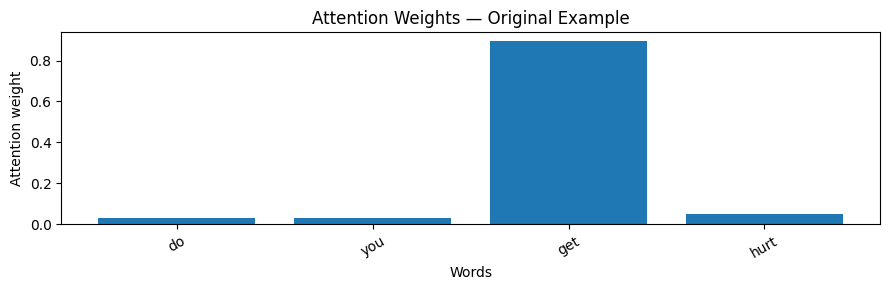

In [6]:
# Original single-question attention demo, corrected to align visible words and tokens.
question = df["question"].iloc[0]
words = tokenizer._words(question) if hasattr(tokenizer, "_words") else question.replace("?", "").split()
with torch.no_grad():
    prediction, weights = model(X[:1])
plt.figure(figsize=(9, 3))
plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights — Original Example")
plt.xlabel("Words")
plt.ylabel("Attention weight")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

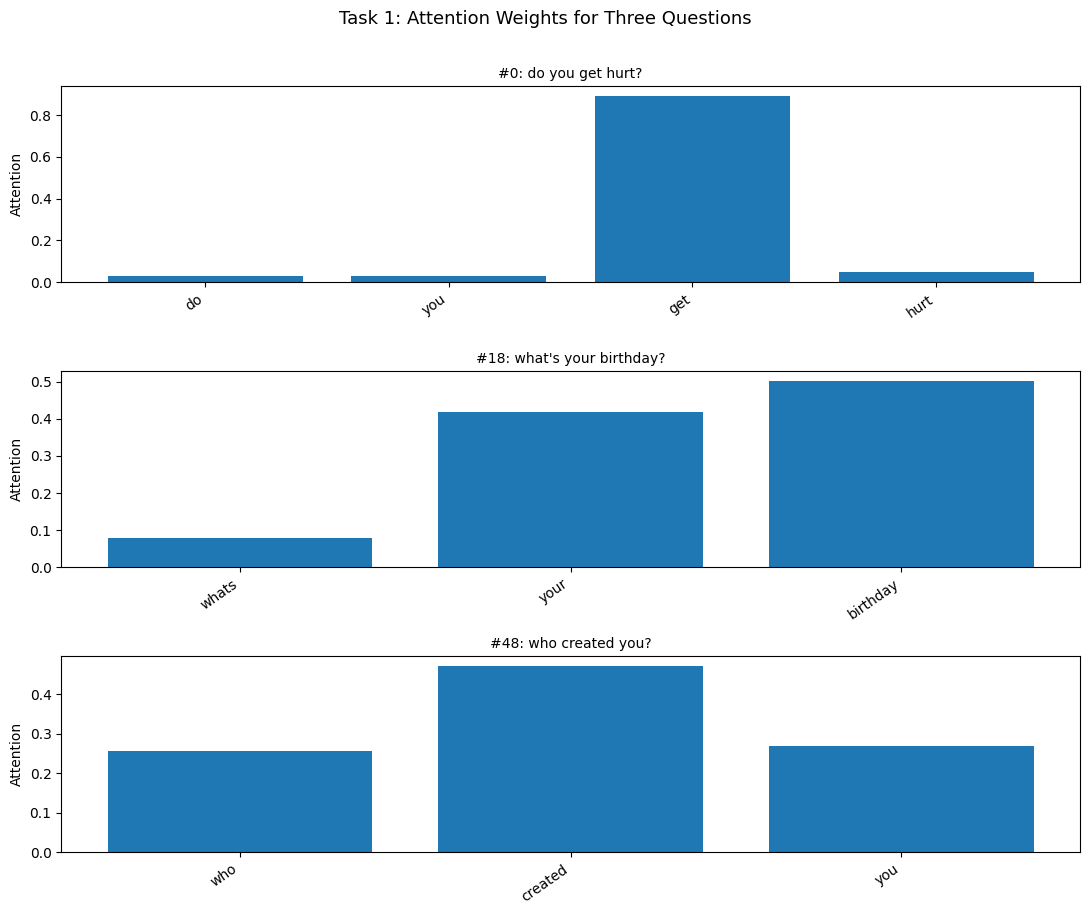

TASK 1 — HIGHEST ATTENTION WORDS
1. do you get hurt?
   Top: 'get' (0.893) | Predicted group: 0 | True group: 0
2. what's your birthday?
   Top: 'birthday' (0.503) | Predicted group: 1 | True group: 1
3. who created you?
   Top: 'created' (0.473) | Predicted group: 3 | True group: 3

OBSERVATION / ANSWER:
The highest-weight word is the model's strongest focus for each chosen question. 
Topic words can help identify the intent (e.g., body, age, or creator), but common
words may also receive high weights, especially with this small training dataset.
Attention weights show where this trained model focuses; they are not proof of causality.


In [7]:
# Task 1: Three different answer groups (body, age, origin/creator).
import numpy as np

question_indices = [0, 18, 48]
task1_results = []

def words_from_question(question_text):
    # Match token positions exactly, including punctuation filtering.
    if hasattr(tokenizer, "_words"):
        return tokenizer._words(question_text)
    from tensorflow.keras.preprocessing.text import text_to_word_sequence
    return text_to_word_sequence(question_text)

def explain_attention(row_index, ax):
    question_text = df.loc[row_index, "question"]
    words = words_from_question(question_text)
    with torch.no_grad():
        logits, scores = model(X[row_index:row_index + 1])
    values = scores[0, :len(words)].cpu().numpy()
    top_pos = int(np.argmax(values))
    predicted_group = int(logits.argmax(dim=1).item())
    ax.bar(range(len(words)), values)
    ax.set_xticks(range(len(words)))
    ax.set_xticklabels(words, rotation=35, ha="right")
    ax.set_ylabel("Attention")
    ax.set_title(f"#{row_index}: {question_text}", fontsize=10)
    return {"question": question_text, "top_word": words[top_pos],
            "top_weight": float(values[top_pos]), "prediction": predicted_group,
            "expected": int(df.loc[row_index, "answer_id"])}

fig, axes = plt.subplots(3, 1, figsize=(11, 9))
for idx, ax in zip(question_indices, axes):
    task1_results.append(explain_attention(idx, ax))
plt.suptitle("Task 1: Attention Weights for Three Questions", y=1.01, fontsize=13)
plt.tight_layout()
plt.show()

print("TASK 1 — HIGHEST ATTENTION WORDS")
for i, item in enumerate(task1_results, 1):
    print(f"{i}. {item['question']}")
    print(f"   Top: '{item['top_word']}' ({item['top_weight']:.3f}) | "
          f"Predicted group: {item['prediction']} | True group: {item['expected']}")

print("\nOBSERVATION / ANSWER:")
print("The highest-weight word is the model's strongest focus for each chosen question. ")
print("Topic words can help identify the intent (e.g., body, age, or creator), but common")
print("words may also receive high weights, especially with this small training dataset.")
print("Attention weights show where this trained model focuses; they are not proof of causality.")

### Task 1 — Written answer (based on the saved output)

| Question | Highest-attention word | Weight | Observation |
|---|---|---:|---|
| Do you get hurt? | **get** | 0.893 | This is a general action word; the model may emphasize it even though **hurt** more clearly expresses the question's topic. |
| What's your birthday? | **birthday** | 0.503 | This word is highly informative about the **age** topic. |
| Who created you? | **created** | 0.473 | This word helps identify a question about the **creator**. |

**Conclusion:** Two of the three highest-attention words are clearly meaningful topic clues. The first example shows that the greatest attention weight does not always fall on the word a human would consider most important. Attention reflects what this small trained model has learned; it does not prove that a word caused the prediction.

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

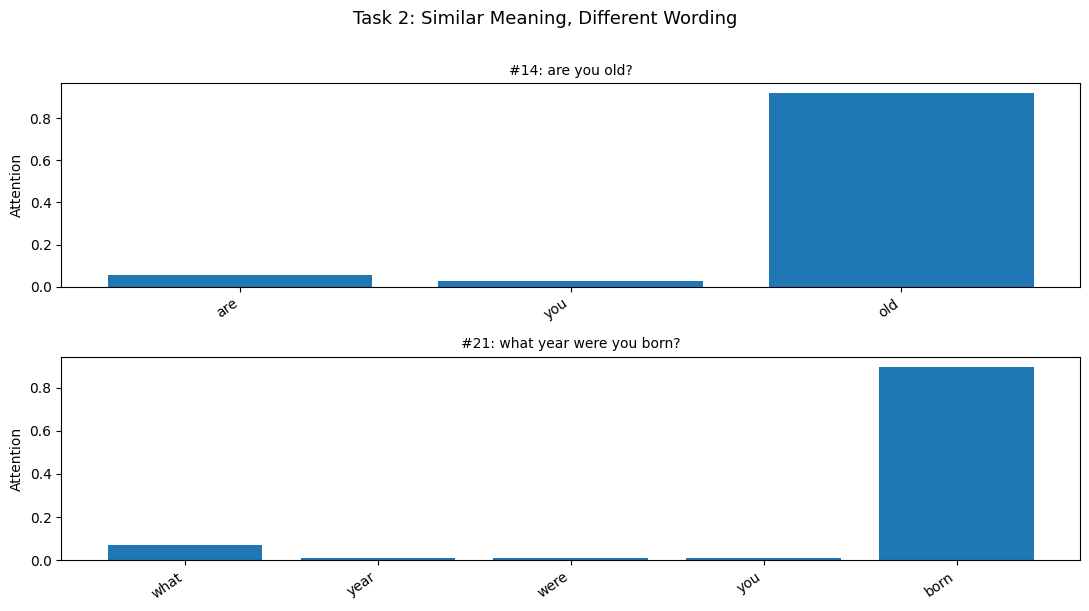

TASK 2 — COMPARISON
Question: are you old?
Highest-weight word: 'old' (weight 0.919); predicted group 1; expected group 1
Question: what year were you born?
Highest-weight word: 'born' (weight 0.899); predicted group 1; expected group 1

The model focuses on DIFFERENT highest-weight words in the two questions.
ANSWER: These questions ask about age, but use different vocabulary.
Attention assigns context-dependent weights to their word representations. A
well-trained model may attend to different surface words while predicting the
same answer category; this example only shows the learned behavior on training examples.


In [8]:
# Task 2: Both questions refer to age (answer_id=1) but use different phrasing.
similar_question_indices = [14, 21]  # "are you old?" vs. "what year were you born?"
task2_results = []
fig, axes = plt.subplots(2, 1, figsize=(11, 6))
for idx, ax in zip(similar_question_indices, axes):
    task2_results.append(explain_attention(idx, ax))
plt.suptitle("Task 2: Similar Meaning, Different Wording", y=1.01, fontsize=13)
plt.tight_layout()
plt.show()

first, second = task2_results
print("TASK 2 — COMPARISON")
for item in task2_results:
    print(f"Question: {item['question']}")
    print(f"Highest-weight word: '{item['top_word']}' "
          f"(weight {item['top_weight']:.3f}); "
          f"predicted group {item['prediction']}; expected group {item['expected']}")

if first['top_word'] == second['top_word']:
    print("\nThe model focuses on the SAME highest-weight word in both questions.")
else:
    print("\nThe model focuses on DIFFERENT highest-weight words in the two questions.")
print("ANSWER: These questions ask about age, but use different vocabulary.")
print("Attention assigns context-dependent weights to their word representations. A")
print("well-trained model may attend to different surface words while predicting the")
print("same answer category; this example only shows the learned behavior on training examples.")

### Task 2 — Written answer (based on the saved output)

The two questions have the **same meaning/category (age)** but use different wording:

- **Are you old?** → highest attention: **old** (0.919), predicted category **1**.
- **What year were you born?** → highest attention: **born** (0.899), predicted category **1**.

**Conclusion:** The model attends to **different words** that carry related age information. This suggests attention can focus on different relevant terms while yielding the same category. These examples were seen during training, so they do not establish that the model generalizes to unseen paraphrases.